# PCA & DCCM - MUC2 Non-glycosylated: D1-D2 and D4-CTCK Domains


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.style.use('seaborn-v0_8-darkgrid')

base       = "/home/computer2/analysis_simulations/analysis/pca_dccm_d1-d2_d4-ctck/"
output_dir = "/home/computer2/analysis_simulations/analysis/plots_domains_noglyc"
os.makedirs(output_dir, exist_ok=True)
print("Output dir:", output_dir)

Output dir: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc


## Load Data

In [2]:
# PCA
d12_proj = pd.read_csv(base + "d1-d2_noglyc_pca_projections.csv")
d12_var  = pd.read_csv(base + "d1-d2_noglyc_variance.csv")
d4_proj  = pd.read_csv(base + "d4_ctck_noglyc_projections.csv")
d4_var   = pd.read_csv(base + "d4_ctck_noglyc_variance.csv")

# DCCM
dccm_d12 = np.loadtxt(base + "muc2_noglyc_d1-d2.txt")
dccm_d4  = np.loadtxt(base + "muc2_d4-ctck_noglyc_dccm.txt")

print(f"D1-D2  PCA projections: {d12_proj.shape}  |  variance PCs: {len(d12_var)}")
print(f"D4-CTCK PCA projections: {d4_proj.shape}  |  variance PCs: {len(d4_var)}")
print(f"D1-D2  DCCM shape: {dccm_d12.shape}")
print(f"D4-CTCK DCCM shape: {dccm_d4.shape}")

D1-D2  PCA projections: (28719, 3)  |  variance PCs: 10
D4-CTCK PCA projections: (28719, 3)  |  variance PCs: 10
D1-D2  DCCM shape: (837, 837)
D4-CTCK DCCM shape: (774, 774)


## PCA - D1-D2

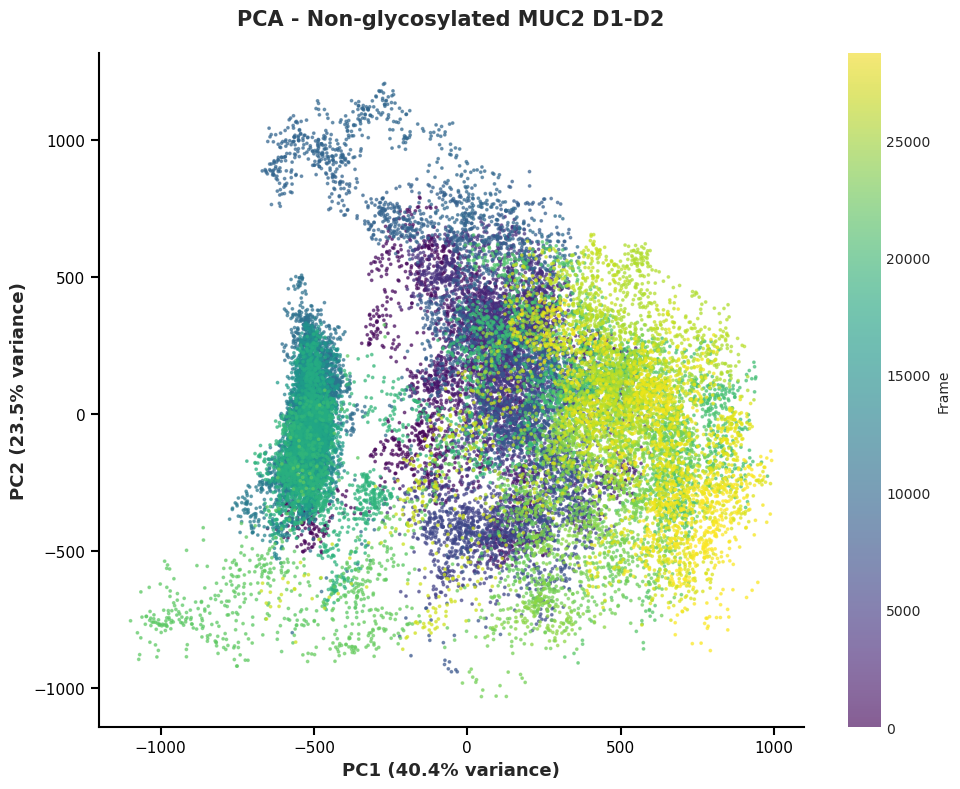

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/pca_noglyc_d1-d2_scatter.png


In [3]:
pct1 = d12_var["variance"].iloc[0] / d12_var["variance"].sum() * 100
pct2 = d12_var["variance"].iloc[1] / d12_var["variance"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
sc = ax.scatter(d12_proj["PC1"], d12_proj["PC2"],
                c=np.arange(len(d12_proj)), cmap="viridis", s=3, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Frame")
ax.set_xlabel(f"PC1 ({pct1:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_ylabel(f"PC2 ({pct2:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_title("PCA - Non-glycosylated MUC2 D1-D2", fontsize=15, fontweight="bold", pad=20)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")
plt.tight_layout()
out = os.path.join(output_dir, "pca_noglyc_d1-d2_scatter.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

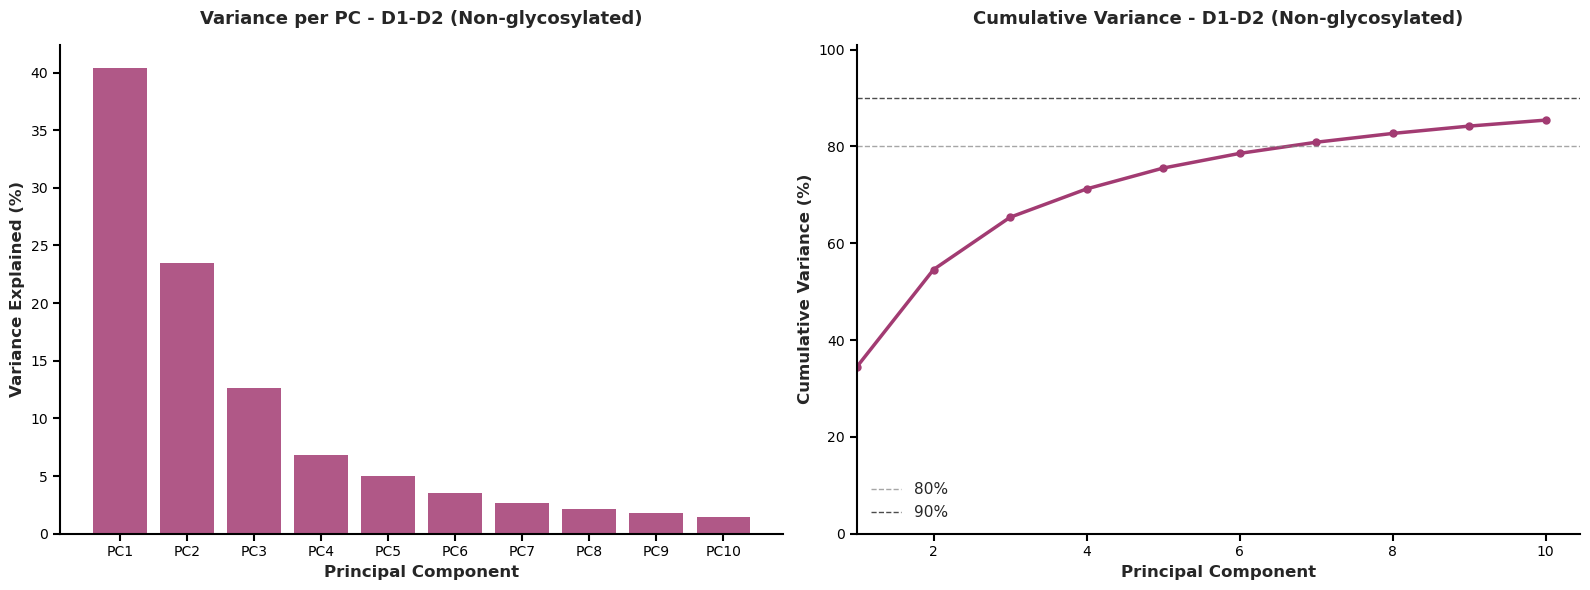

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/pca_noglyc_d1-d2_variance.png


In [4]:
n_pcs = min(10, len(d12_var))
pct = (d12_var["variance"].iloc[:n_pcs] / d12_var["variance"].sum() * 100).values
x = np.arange(n_pcs)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=100)

axes[0].bar(x, pct, color="#A23B72", alpha=0.85)
axes[0].set_xlabel("Principal Component", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Variance Explained (%)", fontsize=12, fontweight="bold")
axes[0].set_title("Variance per PC - D1-D2 (Non-glycosylated)", fontsize=13, fontweight="bold", pad=15)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"PC{i+1}" for i in x])
axes[0].set_ylim(bottom=0)

axes[1].plot(d12_var["PC"], d12_var["cumulative_variance"] * 100,
             linewidth=2.5, color="#A23B72", marker="o", markersize=5)
axes[1].axhline(80, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="80%")
axes[1].axhline(90, color="black", linestyle="--", linewidth=1, alpha=0.7, label="90%")
axes[1].set_xlabel("Principal Component", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Cumulative Variance (%)", fontsize=12, fontweight="bold")
axes[1].set_title("Cumulative Variance - D1-D2 (Non-glycosylated)", fontsize=13, fontweight="bold", pad=15)
axes[1].set_ylim(0, 101); axes[1].set_xlim(left=1); axes[1].legend(fontsize=11)

for ax in axes:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", which="major", labelsize=10, length=5, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_noglyc_d1-d2_variance.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## PCA - D4-CTCK

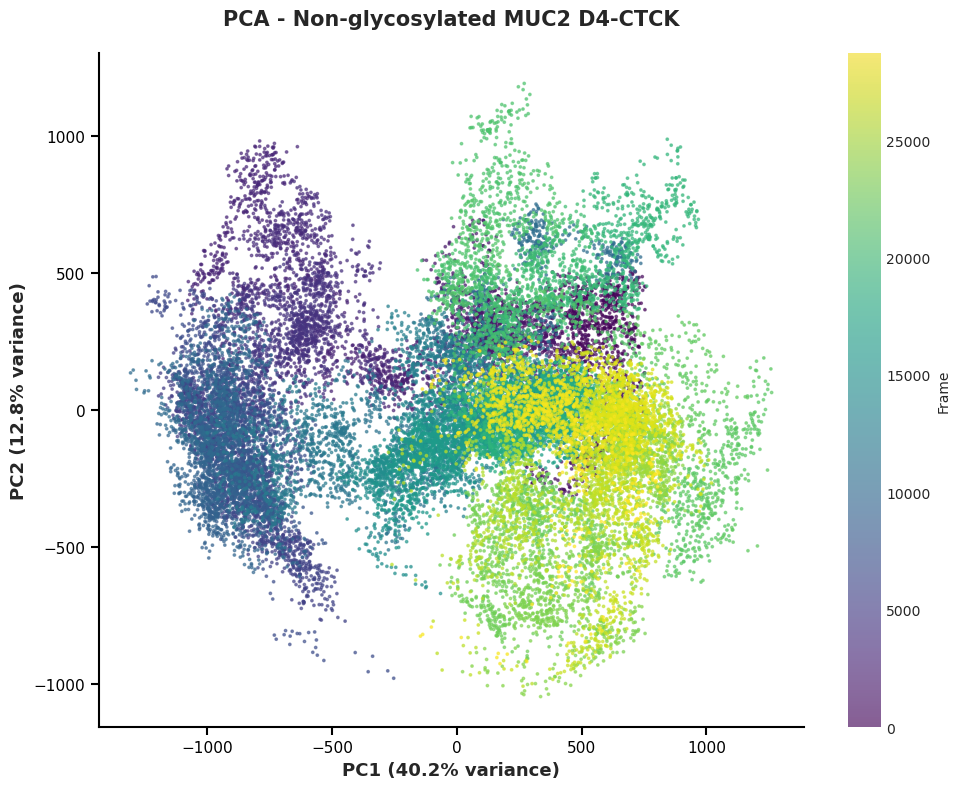

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/pca_noglyc_d4-ctck_scatter.png


In [5]:
pct1 = d4_var["variance"].iloc[0] / d4_var["variance"].sum() * 100
pct2 = d4_var["variance"].iloc[1] / d4_var["variance"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 8), dpi=100)
sc = ax.scatter(d4_proj["PC1"], d4_proj["PC2"],
                c=np.arange(len(d4_proj)), cmap="viridis", s=3, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Frame")
ax.set_xlabel(f"PC1 ({pct1:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_ylabel(f"PC2 ({pct2:.1f}% variance)", fontsize=13, fontweight="bold")
ax.set_title("PCA - Non-glycosylated MUC2 D4-CTCK", fontsize=15, fontweight="bold", pad=20)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", which="major", labelsize=11, length=6, width=1.5, direction="out", colors="black")
plt.tight_layout()
out = os.path.join(output_dir, "pca_noglyc_d4-ctck_scatter.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

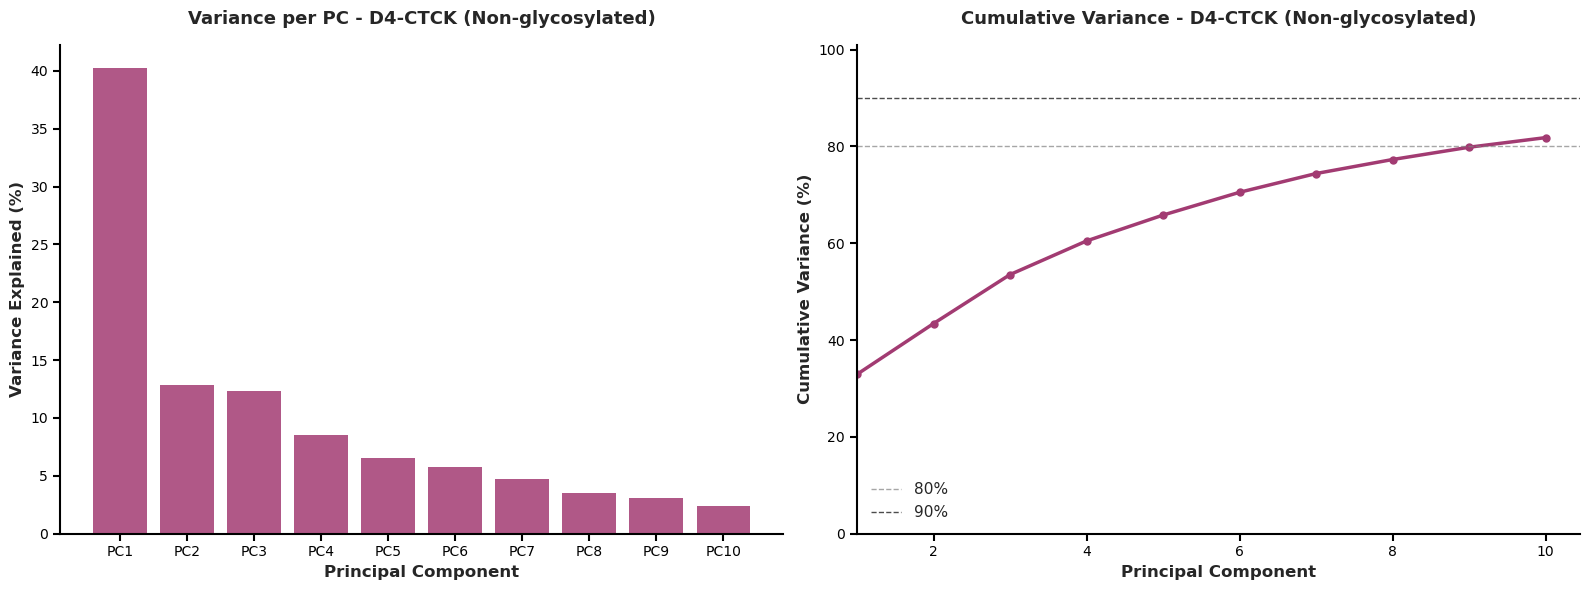

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/pca_noglyc_d4-ctck_variance.png


In [6]:
n_pcs = min(10, len(d4_var))
pct = (d4_var["variance"].iloc[:n_pcs] / d4_var["variance"].sum() * 100).values
x = np.arange(n_pcs)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=100)

axes[0].bar(x, pct, color="#A23B72", alpha=0.85)
axes[0].set_xlabel("Principal Component", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Variance Explained (%)", fontsize=12, fontweight="bold")
axes[0].set_title("Variance per PC - D4-CTCK (Non-glycosylated)", fontsize=13, fontweight="bold", pad=15)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"PC{i+1}" for i in x])
axes[0].set_ylim(bottom=0)

axes[1].plot(d4_var["PC"], d4_var["cumulative_variance"] * 100,
             linewidth=2.5, color="#A23B72", marker="o", markersize=5)
axes[1].axhline(80, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="80%")
axes[1].axhline(90, color="black", linestyle="--", linewidth=1, alpha=0.7, label="90%")
axes[1].set_xlabel("Principal Component", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Cumulative Variance (%)", fontsize=12, fontweight="bold")
axes[1].set_title("Cumulative Variance - D4-CTCK (Non-glycosylated)", fontsize=13, fontweight="bold", pad=15)
axes[1].set_ylim(0, 101); axes[1].set_xlim(left=1); axes[1].legend(fontsize=11)

for ax in axes:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True); ax.spines["left"].set_color("black"); ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_visible(True); ax.spines["bottom"].set_color("black"); ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", which="major", labelsize=10, length=5, width=1.5, direction="out", colors="black")

plt.tight_layout()
out = os.path.join(output_dir, "pca_noglyc_d4-ctck_variance.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

## DCCM - D1-D2 and D4-CTCK

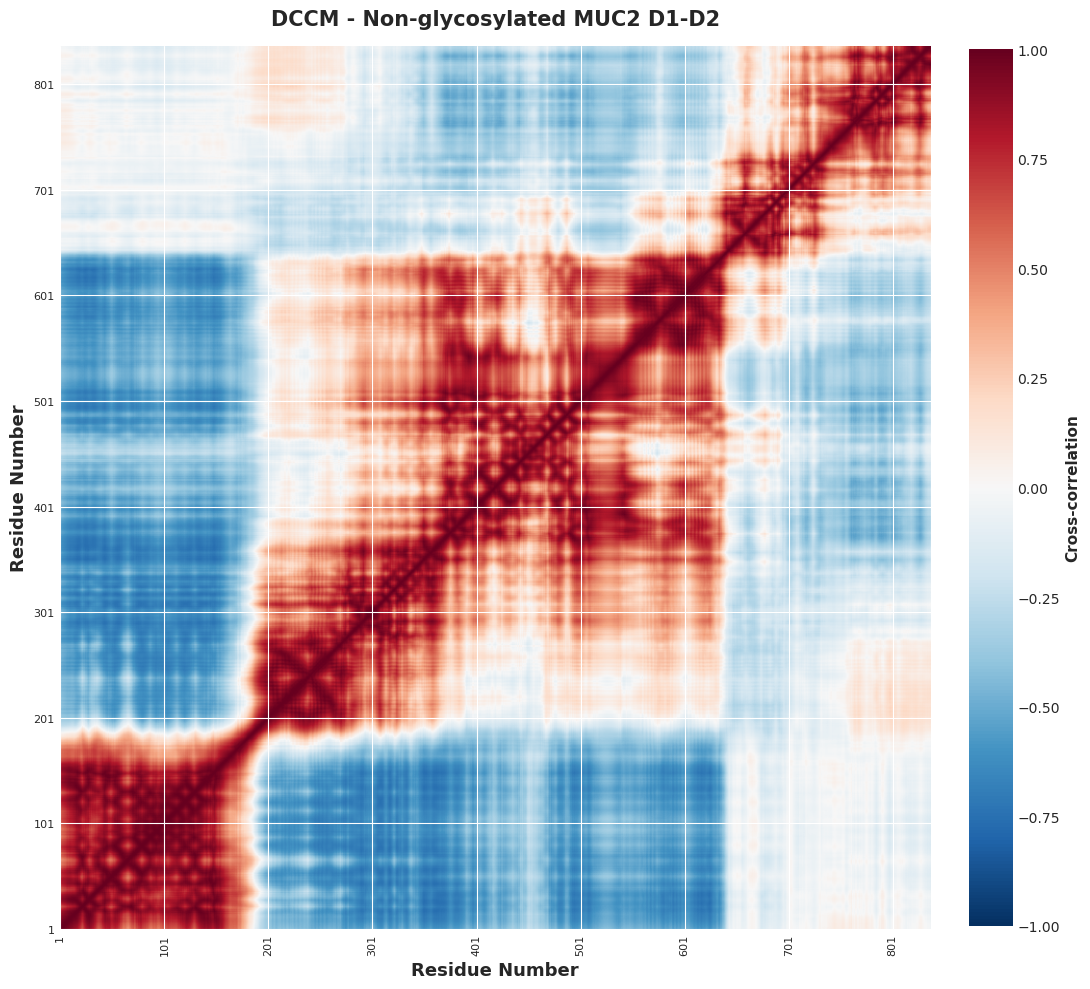

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/dccm_noglyc_d1-d2.png


In [7]:
n = dccm_d12.shape[0]
ticks = np.arange(0, n, 100)
tick_labels = [str(t + 1) for t in ticks]

fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
im = ax.imshow(dccm_d12, cmap="RdBu_r", vmin=-1, vmax=1,
               origin="lower", aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
ax.set_xticks(ticks); ax.set_xticklabels(tick_labels, rotation=90, fontsize=8)
ax.set_yticks(ticks); ax.set_yticklabels(tick_labels, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_title("DCCM - Non-glycosylated MUC2 D1-D2", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_noglyc_d1-d2.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

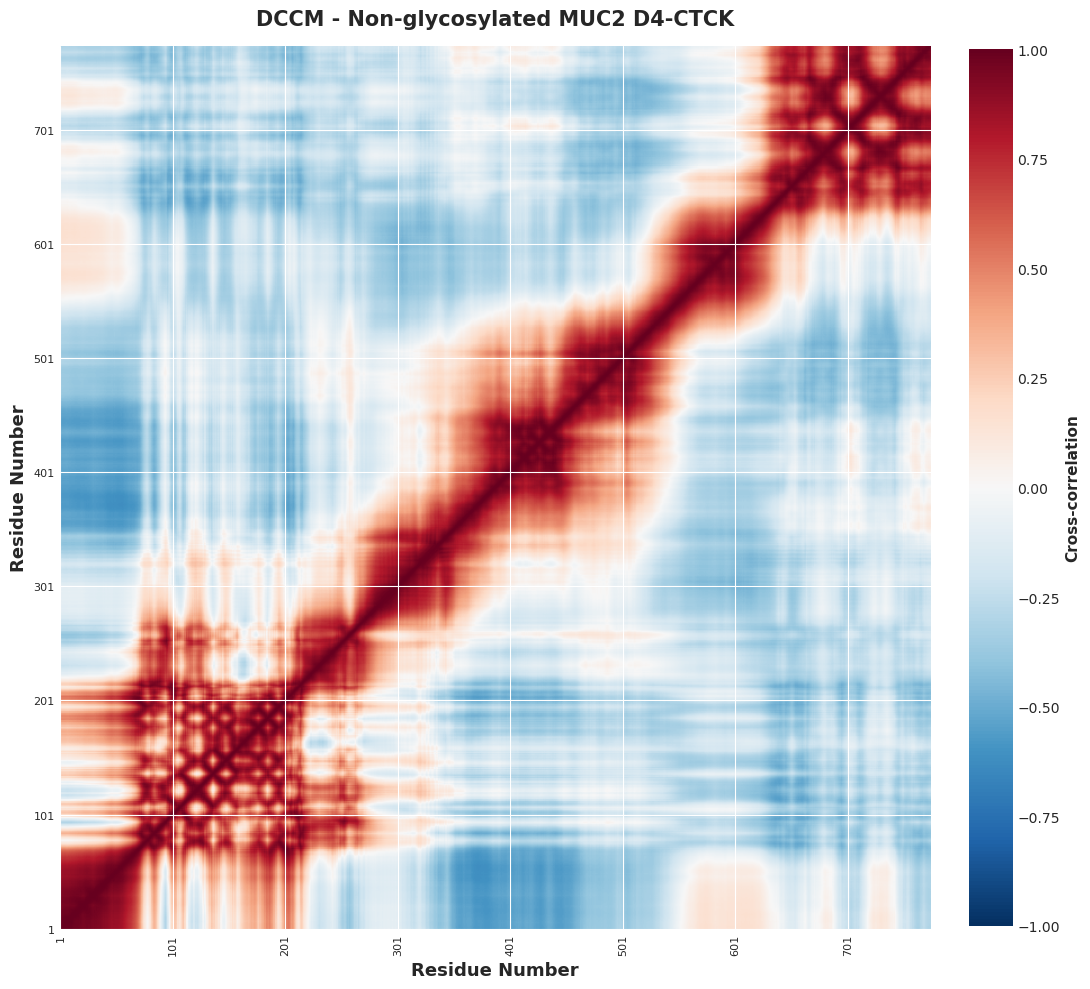

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/dccm_noglyc_d4-ctck.png


In [8]:
n = dccm_d4.shape[0]
ticks = np.arange(0, n, 100)
tick_labels = [str(t + 1) for t in ticks]

fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
im = ax.imshow(dccm_d4, cmap="RdBu_r", vmin=-1, vmax=1,
               origin="lower", aspect="auto")
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
cbar.ax.tick_params(labelsize=10)
ax.set_xticks(ticks); ax.set_xticklabels(tick_labels, rotation=90, fontsize=8)
ax.set_yticks(ticks); ax.set_yticklabels(tick_labels, fontsize=8)
ax.set_xlabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_ylabel("Residue Number", fontsize=13, fontweight="bold")
ax.set_title("DCCM - Non-glycosylated MUC2 D4-CTCK", fontsize=15, fontweight="bold", pad=15)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_noglyc_d4-ctck.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")

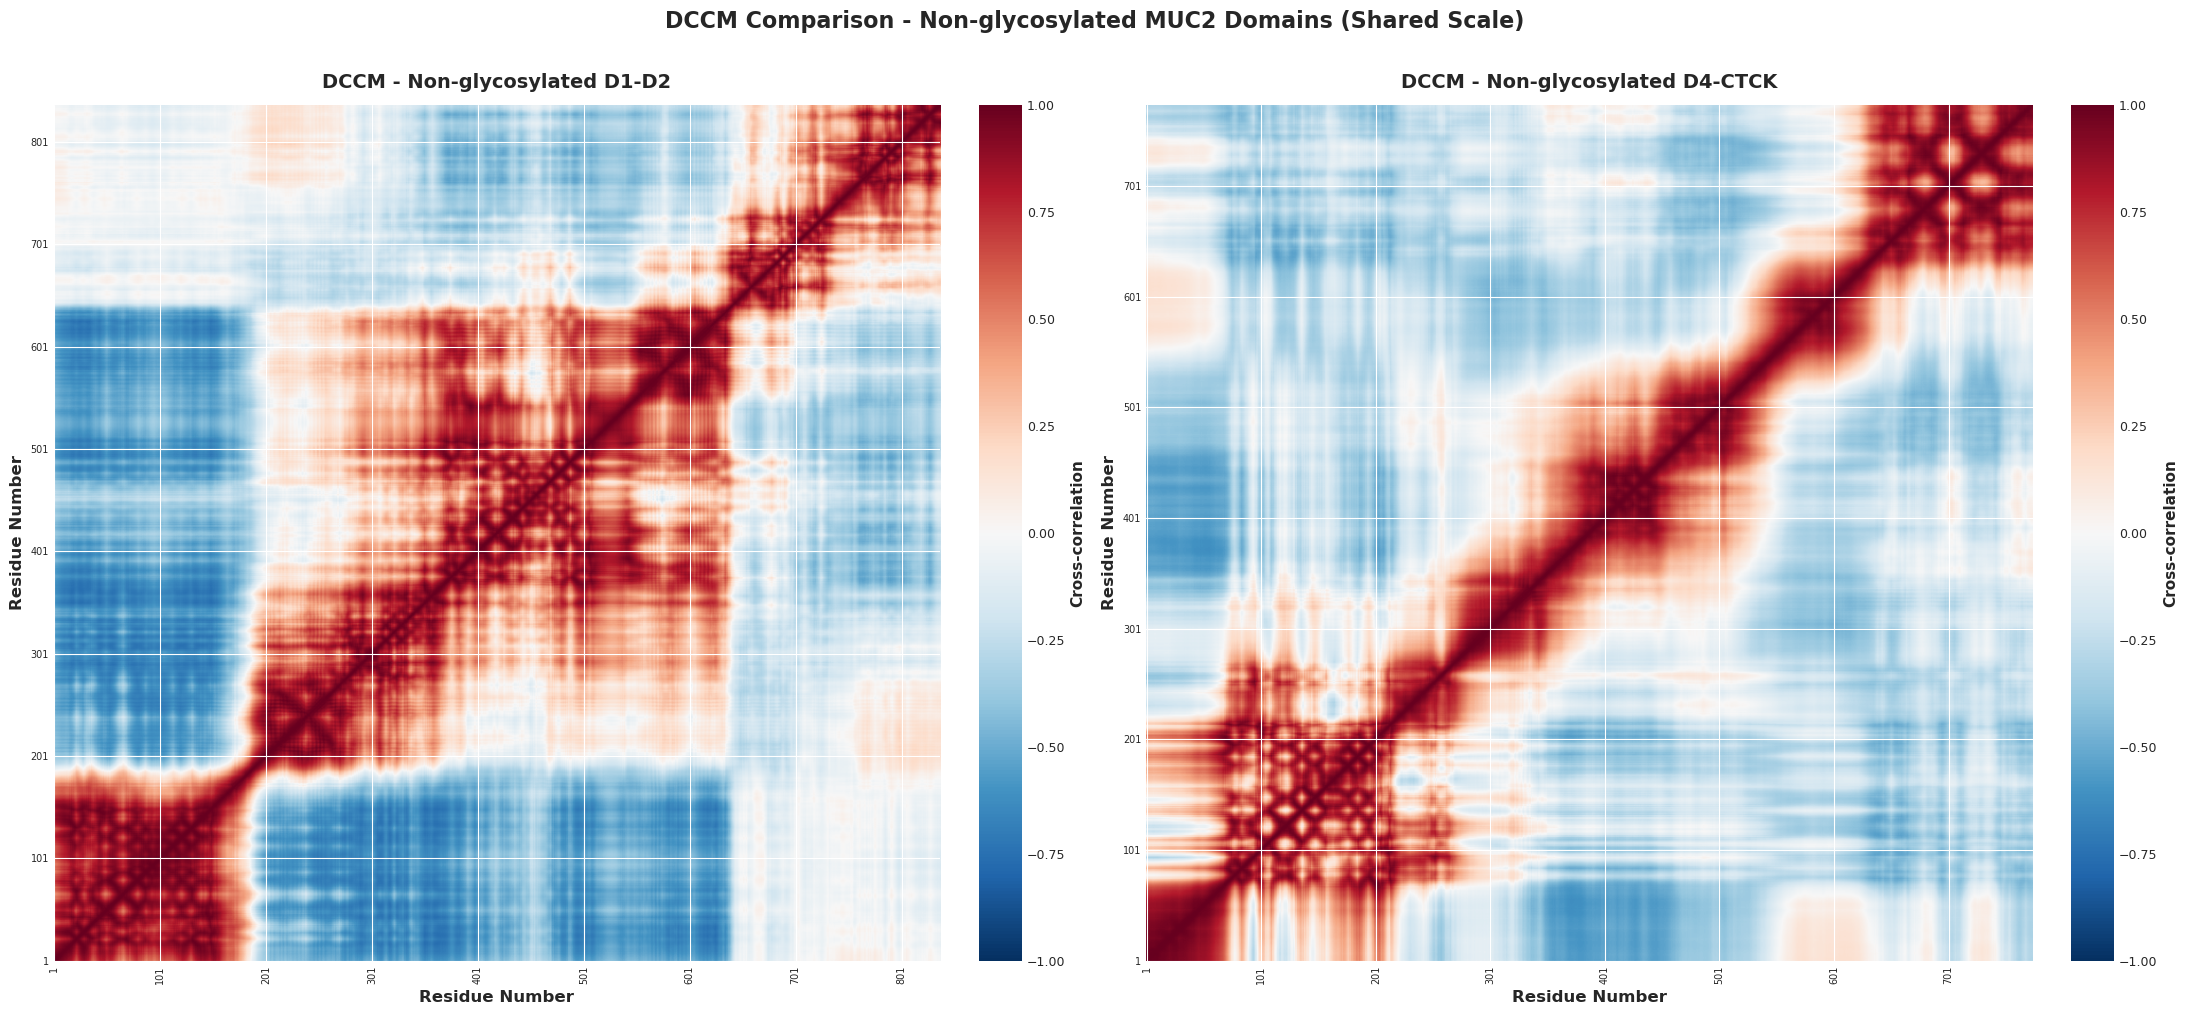

Saved: /home/computer2/analysis_simulations/analysis/plots_domains_noglyc/dccm_noglyc_domains_comparison.png


In [9]:
# Side-by-side DCCM with shared scale
v = max(abs(dccm_d12).max(), abs(dccm_d4).max())

fig, axes = plt.subplots(1, 2, figsize=(22, 10), dpi=100)

for ax, mat, title in zip(axes,
                           [dccm_d12, dccm_d4],
                           ["D1-D2", "D4-CTCK"]):
    n = mat.shape[0]
    ticks = np.arange(0, n, 100)
    tick_labels = [str(t + 1) for t in ticks]
    im = ax.imshow(mat, cmap="RdBu_r", vmin=-v, vmax=v,
                   origin="lower", aspect="auto")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Cross-correlation", fontsize=11, fontweight="bold")
    cbar.ax.tick_params(labelsize=9)
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
    ax.set_yticks(ticks); ax.set_yticklabels(tick_labels, fontsize=7)
    ax.set_xlabel("Residue Number", fontsize=12, fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=12, fontweight="bold")
    ax.set_title(f"DCCM - Non-glycosylated {title}", fontsize=14, fontweight="bold", pad=12)

fig.suptitle("DCCM Comparison - Non-glycosylated MUC2 Domains (Shared Scale)",
             fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_noglyc_domains_comparison.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show(); print(f"Saved: {out}")